<center><h1>Raza_MohammadHasnain_HW7</h1></center>
<br>
<center><font size="4">Support Vector Machines and K-Means Clustering on the Anuran Calls (MFCCs) Data</font></center>

**Name:** Mohammad Hasnain Raza  
**GitHub Username:** hasnainrazaa03  
**USC ID:** 1259246355

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Package imports

In [1]:
# all imports and dependencies
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline
from joblib import Parallel, delayed
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn import config_context
from sklearn.cluster import KMeans
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, multilabel_confusion_matrix, precision_recall_fscore_support, recall_score, roc_auc_score, roc_curve, silhouette_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC, LinearSVC

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# seed used for the split, the CV folds, SMOTE and k-means
SEED = 42

def compact(table, precision=4):
    # small font and tight rows so long tables take less space
    return table.style.format(precision=precision, na_rep="").set_table_styles([{"selector": "td, th", "props": "font-size: 10px !important; padding: 0 4px !important; line-height: 1.15 !important;"}])

def side_by_side(table, precision=4):
    # long table as two blocks next to each other
    half = (len(table) + 1) // 2
    blocks = [table.iloc[:half].reset_index(), table.iloc[half:].reset_index()]
    return compact(pd.concat(blocks, axis=1, keys=["left", "right"]), precision).hide(axis="index")

### (a) Download the Anuran Calls (MFCCs) Data Set

Each row is one syllable of a frog call, described by 22 MFCCs, with three labels (Family, Genus and Species) and the ID of the recording it came from. `RecordID` is not a feature and is dropped. 70% of the rows are chosen at random as the training set.

In [2]:
# relative path
DATA_PATH = "../data/anuran_calls/Frogs_MFCCs.csv"

frogs_df = pd.read_csv(DATA_PATH)
FEATURES = [col for col in frogs_df.columns if col.startswith("MFCCs_")]
LABELS = ["Family", "Genus", "Species"]

# 70% training, 30% test
train_df, test_df = train_test_split(frogs_df, test_size=0.3, random_state=SEED)
train_X, test_X = train_df[FEATURES], test_df[FEATURES]
train_Y, test_Y = train_df[LABELS].reset_index(drop=True), test_df[LABELS].reset_index(drop=True)

print("Full data:", frogs_df.shape, " Training set:", train_X.shape, " Test set:", test_X.shape)
# first three rows, one column per row
display(side_by_side(frogs_df.head(3).T.rename_axis("column")))

Full data: (7195, 26)  Training set: (5036, 22)  Test set: (2159, 22)


In [3]:
# rows in each class, for the whole data and the two sets
counts = pd.concat({label: pd.DataFrame({"all": frogs_df[label].value_counts(), "train": train_Y[label].value_counts(), "test": test_Y[label].value_counts()}) for label in LABELS}, names=["label", "class"])
display(side_by_side(counts))

In [4]:
# the features are already scaled to [-1, 1], but their spreads differ
stats = frogs_df[FEATURES].describe().T[["mean", "std", "min", "max"]].rename_axis("feature")
display(side_by_side(stats, precision=3))
print(f"MFCCs_ 1 is exactly 1 in {(frogs_df['MFCCs_ 1'] == 1).mean():.1%} of the rows")

MFCCs_ 1 is exactly 1 in 96.6% of the rows


### (b) Train a classifier for each label

#### (i) Research

**Answer.** Each instance has $q = 3$ labels (Family, Genus and Species), and $n$ is the number of instances.

- **Exact match ratio:** $\frac{1}{n}\sum_{i=1}^n I(\hat y_i = y_i)$, the fraction of instances with all three labels right. One wrong label makes the whole instance wrong, so this is the strictest measure.
- **Hamming distance** of an instance: how many of its 3 labels are wrong (0 to 3).
- **Hamming loss:** $\frac{1}{nq}\sum_{i=1}^n\sum_{j=1}^q I(\hat y_{ij} \ne y_{ij})$, the fraction of all labels that are wrong. It is the average Hamming distance divided by 3, so an instance with one wrong label still gets partial credit.
- **Hamming score:** 1 minus the Hamming loss, the fraction of labels that are right.

Sorower (2010) defines these for label sets, where the set-based accuracy $|Y_i \cap Z_i|/|Y_i \cup Z_i|$ is sometimes also called the Hamming score. Here each label is a multi-class output, so the labels are compared one at a time. The labels are also nested (each species belongs to one genus and each genus to one family), but binary relevance predicts them separately, so the number of predicted triplets that are not one of the 10 real (family, genus, species) combinations is reported too.

In [5]:
def multilabel_scores(true_Y, pred_Y):
    # compare the three labels of each instance one by one
    wrong = np.asarray(true_Y) != np.asarray(pred_Y)
    return {"exact match (%)": 100 * np.mean(~wrong.any(axis=1)), "Hamming distance": wrong.sum(axis=1).mean(),
            "Hamming loss (%)": 100 * wrong.mean(), "Hamming score (%)": 100 * (1 - wrong.mean())}

# classes of each label, and the (family, genus, species) triplets that exist in the data
CLASSES = {label: np.sort(frogs_df[label].unique()) for label in LABELS}
VALID_TRIPLETS = {tuple(row) for row in frogs_df[LABELS].to_numpy()}

def invalid_triplets(pred_Y):
    # predicted triplets that are not a real species, e.g. a genus from another family
    return sum(tuple(row) not in VALID_TRIPLETS for row in np.asarray(pred_Y))

print("Valid triplets:", len(VALID_TRIPLETS))

Valid triplets: 10


#### (ii) Train a SVM for each of the labels

The Gaussian kernel is $K(x, x') = \exp(-\|x - x'\|^2 / (2\sigma^2))$, so the width $\sigma$ is passed to the SVM as $\gamma = 1/(2\sigma^2)$. Each label gets its own one-versus-all classifier (one binary SVM per class), and $C$ and $\sigma$ are chosen by 10-fold stratified CV accuracy on the training set. For the standardized attributes the scaler is part of the pipeline, so it is fit on the training folds only.

Following footnote 1, the ranges are checked first by fitting on the whole training set at the corners of each grid and looking at the training accuracy. Standardizing makes the squared distances about 40 times larger (the features have standard deviations of about 0.15), so the standardized grid uses wider kernels.

In [6]:
# param names inside the pipelines
C_KEY = "onevsrestclassifier__estimator__C"
GAMMA_KEY = "onevsrestclassifier__estimator__gamma"
RAW_SIGMAS = np.round(np.arange(0.2, 2.01, 0.1), 1)
STD_SIGMAS = np.arange(1.0, 10.01, 0.5)

def gaussian_svm(standardize):
    svm = OneVsRestClassifier(SVC(kernel="rbf"))
    return make_pipeline(StandardScaler(), svm) if standardize else make_pipeline(svm)

def to_gamma(sigma):
    return 1 / (2 * np.asarray(sigma, dtype=float) ** 2)

def to_sigma(gamma):
    return np.sqrt(1 / (2 * np.asarray(gamma, dtype=float)))

# average squared distance between rows, raw and standardized
sample = train_X.to_numpy()[:1000]
scaled = StandardScaler().fit(train_X).transform(train_X)[:1000]
print(f"mean squared distance: raw {np.mean(((sample[:, None] - sample[None]) ** 2).sum(axis=2)):.2f}, standardized {np.mean(((scaled[:, None] - scaled[None]) ** 2).sum(axis=2)):.2f}")

# footnote 1: training accuracy on the whole training set at the corners of each grid
corner_rows = []
for standardize, sigmas in [(False, RAW_SIGMAS), (True, STD_SIGMAS)]:
    for C in [0.01, 0.1, 1e5]:
        for sigma in [sigmas[0], sigmas[-1]]:
            row = {"attributes": "standardized" if standardize else "raw", "C": f"{C:g}", "sigma": f"{sigma:g}"}
            for label in LABELS:
                model = gaussian_svm(standardize).set_params(**{C_KEY: C, GAMMA_KEY: to_gamma(sigma)})
                row[label] = model.fit(train_X, train_Y[label]).score(train_X, train_Y[label])
            corner_rows.append(row)
display(side_by_side(pd.DataFrame(corner_rows).set_index(["attributes", "C", "sigma"])))

mean squared distance: raw 1.08, standardized 46.19


At $C = 0.01$ the training accuracy falls below 70% at the widest raw kernel ($\sigma = 2$, all three labels) and at the narrowest standardized kernel ($\sigma = 1$, Genus and Species). At $C = 0.1$ every corner stays above 70% (the lowest is 87.0%), and at $C = 10^5$ every corner fits the training set perfectly, so a larger $C$ would not change anything. So the grids are $\log_{10} C \in \{-1, 0, \dots, 5\}$, with $\sigma \in \{0.2, 0.3, \dots, 2.0\}$ for the raw attributes and $\sigma \in \{1.0, 1.5, \dots, 10.0\}$ for the standardized ones (19 widths each).

In [7]:
# 10-fold stratified CV split used for all tuning in question 1
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
SVM_CS = 10.0 ** np.arange(-1, 6)

# test results of every classifier, used for the comparisons in (iv) to (vi)
results = {}
test_preds = {}
test_scores = {}

# short names so the comparison tables fit the page
SHORT_NAMES = {"Gaussian SVM (raw)": "Gauss raw", "Gaussian SVM (standardized)": "Gauss std", "L1 linear SVM": "L1", "L1 linear SVM + SMOTE": "L1+SMOTE", "Classifier chain": "chain"}
SHORT_COLUMNS = {"exact match (%)": "exact", "Hamming distance": "distance", "Hamming loss (%)": "loss", "Hamming score (%)": "score", "balanced accuracy (%)": "bal acc", "invalid triplets": "invalid"}

def short_table(table):
    return table.rename(index=SHORT_NAMES, columns=SHORT_COLUMNS)

def tune(model, grid):
    # one grid search per label
    return {label: GridSearchCV(model, grid, cv=folds, n_jobs=-1).fit(train_X, train_Y[label]) for label in LABELS}

def gaussian_params(search):
    return {"C": search.best_params_[C_KEY], "sigma": to_sigma(search.best_params_[GAMMA_KEY])}

def label_table(searches, params):
    # chosen parameters, CV accuracy and test accuracy of each label
    rows = {}
    for label, search in searches.items():
        test_pred = search.predict(test_X)
        rows[label] = {**params(search), "CV acc (%)": 100 * search.best_score_, "test acc (%)": 100 * np.mean(test_pred == test_Y[label]),
                       "test bal acc (%)": 100 * balanced_accuracy_score(test_Y[label], test_pred)}
    display(compact(pd.DataFrame.from_dict(rows, orient="index")))

def evaluate(name, searches):
    # predict the three labels with the refit models and score them together
    train_pred = pd.DataFrame({label: searches[label].predict(train_X) for label in LABELS})
    test_preds[name] = pd.DataFrame({label: searches[label].predict(test_X) for label in LABELS})
    test_scores[name] = {label: searches[label].decision_function(test_X) for label in LABELS}
    results[name] = multilabel_scores(test_Y, test_preds[name])
    results[name]["balanced accuracy (%)"] = np.mean([100 * balanced_accuracy_score(test_Y[label], test_preds[name][label]) for label in LABELS])
    results[name]["invalid triplets"] = invalid_triplets(test_preds[name])
    train_res = multilabel_scores(train_Y, train_pred)
    print(f"train  exact match = {train_res['exact match (%)']:.2f}%, Hamming loss = {train_res['Hamming loss (%)']:.2f}%")
    print(f"test   exact match = {results[name]['exact match (%)']:.2f}%, Hamming loss = {results[name]['Hamming loss (%)']:.2f}%, invalid triplets = {results[name]['invalid triplets']}")

def plot_gaussian_grid(searches, title):
    fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
    for ax, label in zip(axes, LABELS):
        cv = searches[label].cv_results_
        grid = pd.DataFrame({"log10(C)": np.log10(cv[f"param_{C_KEY}"].astype(float)), "sigma": np.round(to_sigma(cv[f"param_{GAMMA_KEY}"].astype(float)), 2), "accuracy": 100 * cv["mean_test_score"]})
        sns.heatmap(grid.pivot(index="sigma", columns="log10(C)", values="accuracy"), annot=True, fmt=".1f", annot_kws={"fontsize": 6}, yticklabels=True, cmap="viridis", cbar_kws={"label": "10-fold CV accuracy (%)"}, ax=ax)
        ax.set_title(label)
        ax.tick_params(axis="y", labelsize=8, rotation=0)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

**Raw attributes**

,C,sigma,CV acc (%),test acc (%),test bal acc (%)
Family,100.0000,0.4000,99.2652,99.4905,97.8238
Genus,10.0000,0.4000,99.1858,99.1663,96.1543
Species,10.0000,0.4000,99.1264,99.0736,96.8130


train  exact match = 100.00%, Hamming loss = 0.00%
test   exact match = 98.93%, Hamming loss = 0.76%, invalid triplets = 11


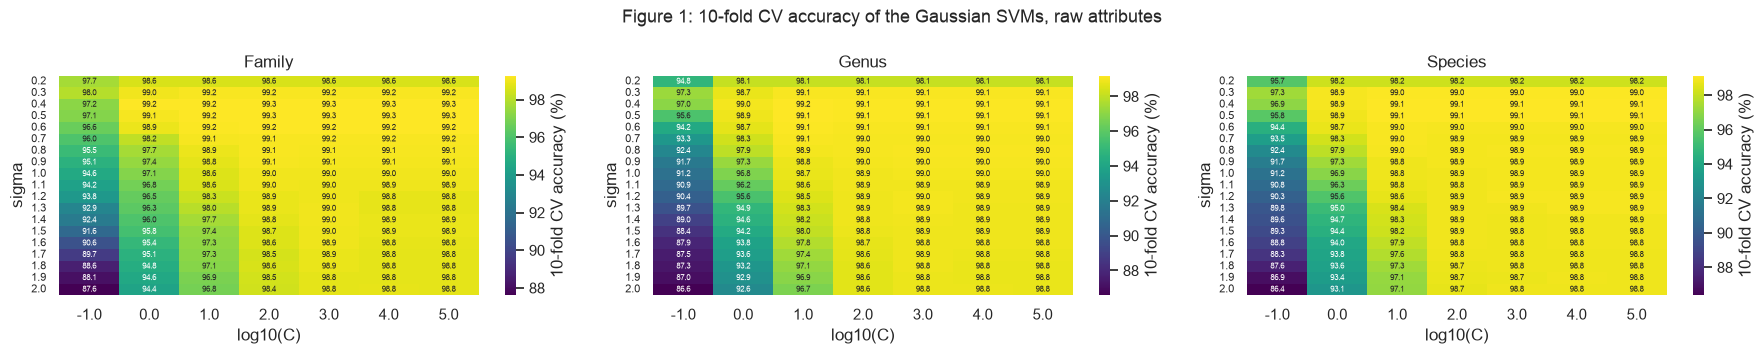

In [8]:
raw_searches = tune(gaussian_svm(standardize=False), {C_KEY: SVM_CS, GAMMA_KEY: to_gamma(RAW_SIGMAS)})
label_table(raw_searches, gaussian_params)
evaluate("Gaussian SVM (raw)", raw_searches)
plot_gaussian_grid(raw_searches, "Figure 1: 10-fold CV accuracy of the Gaussian SVMs, raw attributes")

**Standardized attributes**

,C,sigma,CV acc (%),test acc (%),test bal acc (%)
Family,100.0000,3.0000,99.2056,99.3979,97.8793
Genus,10.0000,3.0000,99.1858,98.7957,94.9713
Species,10.0000,3.5000,99.1066,98.7957,95.7336


train  exact match = 99.98%, Hamming loss = 0.01%
test   exact match = 98.66%, Hamming loss = 1.00%, invalid triplets = 15


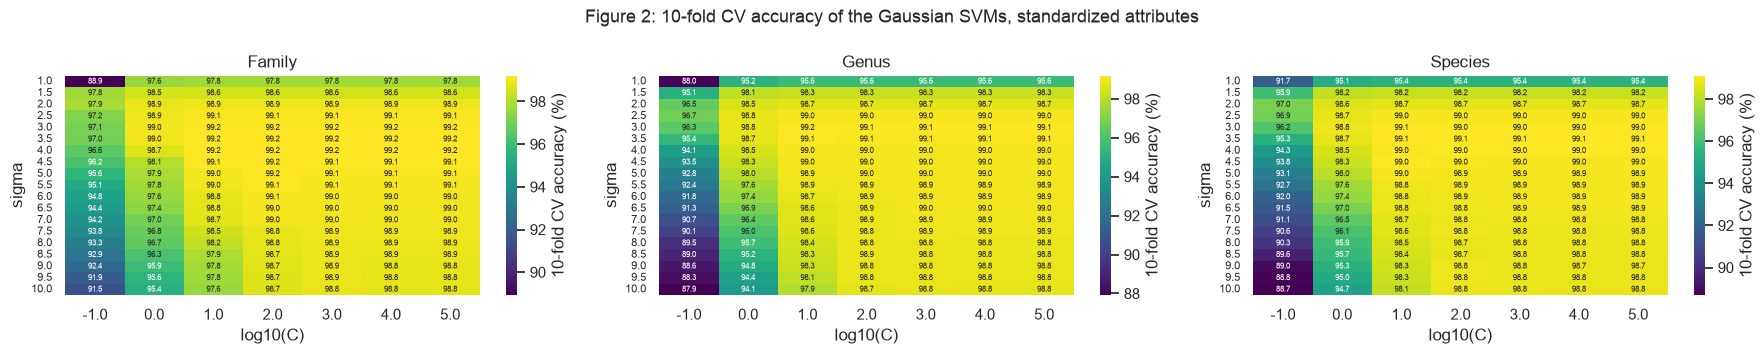

In [9]:
std_searches = tune(gaussian_svm(standardize=True), {C_KEY: SVM_CS, GAMMA_KEY: to_gamma(STD_SIGMAS)})
label_table(std_searches, gaussian_params)
evaluate("Gaussian SVM (standardized)", std_searches)
plot_gaussian_grid(std_searches, "Figure 2: 10-fold CV accuracy of the Gaussian SVMs, standardized attributes")

**Answer.** With the raw attributes CV picks $\sigma = 0.4$ for all three labels, with $C = 100$ for Family and $C = 10$ for Genus and Species. Every label is above 99% test accuracy, and the **exact match ratio is 98.93% and the Hamming loss 0.76%** on the test set. The standardized attributes give 98.66% and 1.00%. Both fit the training set almost perfectly.

The CV accuracy is about 99% over a wide area with $C \ge 10$ and a narrow kernel (Figures 1 and 2), so many settings are nearly tied. It only drops when a small $C$ meets a wide kernel, where the boundary is too smooth. The two chosen widths agree with each other. Standardizing stretches the distances by about $\sqrt{46.19/1.08} \approx 6.5$, and $\sigma = 3$ on the standardized scale is about $\sigma = 0.46$ on the raw scale.

**Standardizing does not help**, and it is slightly worse on the test set. The MFCCs are already scaled to $[-1, 1]$ (footnote 2). Standardizing gives full weight to coefficients that barely vary, like `MFCCs_ 1`, which is exactly 1 in 96.6% of the rows, so small noise in them counts as much as the informative coefficients. The raw attributes are used for the Gaussian SVM from here on.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

Following footnote 3, the L1 penalty is used with a linear kernel. For each class against the rest the linear SVM minimizes $\|w\|_1 + C \sum_i \max(0, 1 - y_i w^T x_i)^2$, so a smaller $C$ means a stronger penalty and more zero weights. The attributes are standardized inside the pipeline, and $C$ is chosen from $\log_{10} C \in \{-3, -2.5, \dots, 2\}$ by 10-fold CV.

,C,nonzero,CV acc (%),test acc (%),test bal acc (%)
Family,10.0000,88 of 88,94.1223,92.8208,69.0223
Genus,100.0000,176 of 176,95.1551,94.1640,76.9036
Species,10.0000,220 of 220,96.0682,95.9240,89.4759


train  exact match = 92.51%, Hamming loss = 4.52%
test   exact match = 91.25%, Hamming loss = 5.70%, invalid triplets = 121
C = 0.001  non-zero weights: Family 24, Genus 21, Species 35


C = 0.01   non-zero weights: Family 47, Genus 86, Species 111


C = 0.1    non-zero weights: Family 81, Genus 147, Species 187


C = 1      non-zero weights: Family 87, Genus 171, Species 216


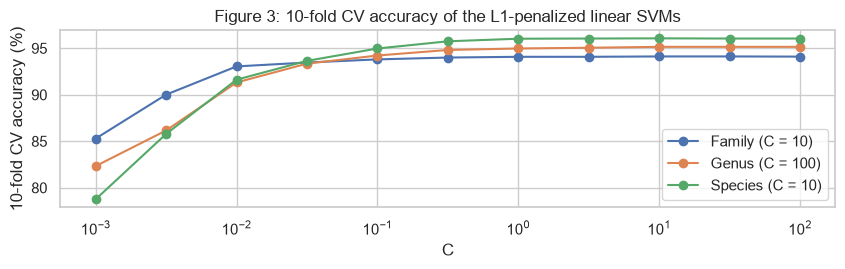

In [10]:
L1_CS = 10.0 ** np.arange(-3, 2.01, 0.5)

def l1_svm(smote, C=1.0):
    svm = LinearSVC(penalty="l1", dual=False, C=C, max_iter=100000, random_state=SEED)
    return make_pipeline(StandardScaler(), SMOTE(random_state=SEED), svm) if smote else make_pipeline(StandardScaler(), svm)

def l1_params(search):
    # chosen C and how many weights are not zero
    coef = search.best_estimator_[-1].coef_
    return {"C": search.best_params_["linearsvc__C"], "nonzero": f"{(coef != 0).sum()} of {coef.size}"}

def plot_l1_cv(searches, title):
    plt.figure(figsize=(10, 2.3))
    for label, search in searches.items():
        plt.semilogx(L1_CS, 100 * search.cv_results_["mean_test_score"], marker="o", label=f"{label} (C = {search.best_params_['linearsvc__C']:g})")
    plt.xlabel("C")
    plt.ylabel("10-fold CV accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.show()

l1_searches = tune(l1_svm(smote=False), {"linearsvc__C": L1_CS})
label_table(l1_searches, l1_params)
evaluate("L1 linear SVM", l1_searches)

# non-zero weights for smaller C, fit on the whole training set
for C in [0.001, 0.01, 0.1, 1]:
    counts = [f"{label} {(l1_svm(smote=False, C=C).fit(train_X, train_Y[label])[-1].coef_ != 0).sum()}" for label in LABELS]
    print(f"C = {C:<5}  non-zero weights: " + ", ".join(counts))
plot_l1_cv(l1_searches, "Figure 3: 10-fold CV accuracy of the L1-penalized linear SVMs")

**Answer.** CV picks $C = 10$ (Family), $100$ (Genus) and $10$ (Species). The **exact match ratio is 91.25% and the Hamming loss 5.70%** on the test set, far worse than the Gaussian SVM (0.76%), so a linear boundary is too simple here. Figure 3 shows the CV accuracy rising until about $C = 1$ and then staying flat. For smaller $C$ the penalty sets more and more weights to zero (at $C = 0.001$ only 24 of the 88 Family weights are left) and the accuracy drops. At the chosen $C$ no weight is zero, since with 5036 rows the penalty is weak next to the loss.

Species is the easiest label for this model and Family the hardest, even though Family has only 4 classes. A family is a union of species, and one hyperplane often cannot split it from the other families. The balanced accuracy is much lower than the accuracy, so the small classes are the ones being missed, and **not one Bufonidae test row is found** (recall 0 in the table in (iv)). The three separate predictions also give 121 impossible triplets.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

SMOTE makes new rows for every class except the largest one, on the line between a row and one of its 5 nearest neighbours of the same class, until every class has as many rows as the largest. It sits inside the pipeline after the scaler, so in each CV split only the 9 training folds are oversampled and the held-out fold keeps its real rows. Each label is oversampled on its own.

Family: 5036 rows -> 12292 rows, 3073 in each of the 4 classes


Genus: 5036 rows -> 23192 rows, 2899 in each of the 8 classes
Species: 5036 rows -> 24470 rows, 2447 in each of the 10 classes


,C,nonzero,CV acc (%),test acc (%),test bal acc (%)
Family,3.1623,86 of 88,92.3156,90.9217,91.3069
Genus,1.0000,175 of 176,91.2837,90.2270,91.6202
Species,3.1623,220 of 220,95.8103,95.7851,92.7611


train  exact match = 86.97%, Hamming loss = 6.38%
test   exact match = 85.36%, Hamming loss = 7.69%, invalid triplets = 263


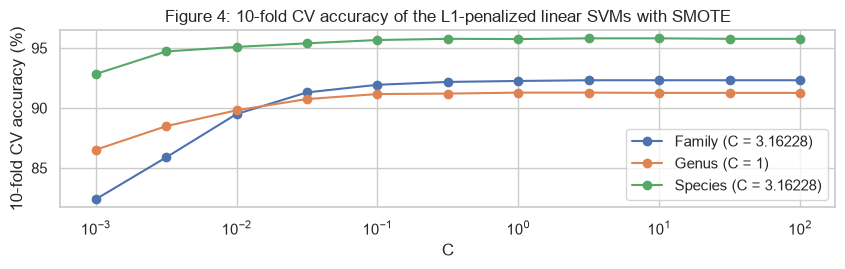

In [11]:
# class counts in the training set after SMOTE
for label in LABELS:
    _, smote_y = SMOTE(random_state=SEED).fit_resample(StandardScaler().fit_transform(train_X), train_Y[label])
    print(f"{label}: {len(train_Y)} rows -> {len(smote_y)} rows, {smote_y.value_counts().iloc[0]} in each of the {smote_y.nunique()} classes")

smote_searches = tune(l1_svm(smote=True), {"linearsvc__C": L1_CS})
label_table(smote_searches, l1_params)
evaluate("L1 linear SVM + SMOTE", smote_searches)
plot_l1_cv(smote_searches, "Figure 4: 10-fold CV accuracy of the L1-penalized linear SVMs with SMOTE")

In [12]:
# recall of each class on the test set, without and with SMOTE
recall_tables = {}
for label in LABELS:
    recall_tables[label] = pd.DataFrame({"test rows": test_Y[label].value_counts().reindex(CLASSES[label])})
    for name in ["L1 linear SVM", "L1 linear SVM + SMOTE"]:
        recall_tables[label][SHORT_NAMES[name]] = 100 * recall_score(test_Y[label], test_preds[name][label], labels=CLASSES[label], average=None, zero_division=0)
print("Recall (%) of each class on the test set:")
display(side_by_side(pd.concat(recall_tables, names=["label", "class"]), precision=1))

# all classifiers on the test set
print("Test set (exact, loss, score and bal acc in %):")
display(compact(short_table(pd.DataFrame.from_dict(results, orient="index"))))

Recall (%) of each class on the test set:


Test set (exact, loss, score and bal acc in %):


,exact,distance,loss,score,bal acc,invalid
Gauss raw,98.9347,0.0227,0.7565,99.2435,96.9303,11
Gauss std,98.6568,0.0301,1.0036,98.9964,96.1947,15
L1,91.2459,0.1709,5.6971,94.3029,78.4673,121
L1+SMOTE,85.3636,0.2307,7.6887,92.3113,91.8961,263


**Answer.** With SMOTE inside the CV, $C = 3.16$ (Family), $1$ (Genus) and $3.16$ (Species) are chosen. **SMOTE trades accuracy on the large classes for recall on the small ones.** The average balanced accuracy goes up from 78.47% to 91.90%. Bufonidae recall goes from 0 to 88.9%, Rhinella from 25.9% to 92.6% and Osteocephalus from 50.0% to 88.2%. The large classes lose recall (Adenomera drops from 97.8% to 89.1%), and since they hold most of the rows, the exact match ratio falls from 91.25% to 85.36% and the Hamming loss rises from 5.70% to 7.69%.

**Conclusions.**

- The **Gaussian SVM on the raw attributes is the best classifier** by every measure in the summary table (exact match 98.93%, Hamming loss 0.76%, balanced accuracy 96.93%). The classes need a non-linear boundary.
- Standardizing is not needed, since the MFCCs are already on a common scale.
- The L1-penalized linear SVM underfits, and at the chosen $C$ its penalty removes no features, so it does not even give a simpler model in return.
- Class imbalance mostly hurts the weak linear model. The Gaussian SVM already reaches a balanced accuracy of 96.93% with no correction. SMOTE is worth it for the linear model only if every class matters equally.
- Binary relevance ignores that the labels are nested, so some predicted triplets are impossible (11 for the best model, 263 with SMOTE). Part (v) tries a classifier chain for this.

#### (v) Classifier Chain - Extra Practice

A **classifier chain** (Read et al., 2011) puts the labels in an order and trains one classifier per label, where classifier $j$ also gets labels $1, \dots, j-1$ as inputs. The true earlier labels are used for training, and the predictions of the earlier classifiers are used at prediction time. Unlike binary relevance, this lets a label depend on the ones before it. The labels here are nested, so the natural order is Family, then Genus, then Species. The earlier labels are added as one-hot columns, and each link is a Gaussian SVM on the raw attributes with the $C$ and $\sigma$ chosen in (ii).

In [13]:
def one_hot(values, label):
    return (np.asarray(values)[:, None] == CLASSES[label]).astype(float)

# chain Family -> Genus -> Species with the Gaussian SVMs from (ii), raw attributes
chain_train, chain_test = train_X.to_numpy(), test_X.to_numpy()
chain_pred, chain_scores = {}, {}
for label in LABELS:
    params = raw_searches[label].best_params_
    svm = OneVsRestClassifier(SVC(kernel="rbf", C=params[C_KEY], gamma=params[GAMMA_KEY])).fit(chain_train, train_Y[label])
    chain_pred[label] = svm.predict(chain_test)
    chain_scores[label] = svm.decision_function(chain_test)
    # true labels are added on the training side and predicted labels on the test side
    chain_train = np.hstack([chain_train, one_hot(train_Y[label], label)])
    chain_test = np.hstack([chain_test, one_hot(chain_pred[label], label)])

test_preds["Classifier chain"] = pd.DataFrame(chain_pred)
test_scores["Classifier chain"] = chain_scores
chain_results = multilabel_scores(test_Y, test_preds["Classifier chain"])
chain_results["balanced accuracy (%)"] = np.mean([100 * balanced_accuracy_score(test_Y[label], chain_pred[label]) for label in LABELS])
chain_results["invalid triplets"] = invalid_triplets(test_preds["Classifier chain"])
chain_table = pd.DataFrame.from_dict({"Gaussian SVM (raw)": results["Gaussian SVM (raw)"], "Classifier chain": chain_results}, orient="index")
print("Binary relevance vs classifier chain, test set (% except distance):")
display(compact(short_table(chain_table)))

# how many of the 3 labels are wrong in each test instance
wrong_counts = {name: pd.Series((np.asarray(test_Y) != np.asarray(test_preds[name])).sum(axis=1)).value_counts().reindex(range(4), fill_value=0) for name in ["Gaussian SVM (raw)", "Classifier chain"]}
print("Test instances by number of wrong labels:")
display(compact(short_table(pd.DataFrame(wrong_counts).T)))

Binary relevance vs classifier chain, test set (% except distance):


,exact,distance,loss,score,bal acc,invalid
Gauss raw,98.9347,0.0227,0.7565,99.2435,96.9303,11
chain,98.9810,0.0245,0.8183,99.1817,96.7950,5


Test instances by number of wrong labels:


,0,1,2,3
Gauss raw,2136,6,8,9
chain,2137,2,9,11


**Answer.** The chain gets an exact match ratio of **98.98%** (binary relevance 98.93%) and a Hamming loss of **0.82%** (0.76%), so the two are about the same. The chain is more consistent, with 5 impossible triplets instead of 11, because Genus and Species can use the predicted family. The cost is that a wrong family now pulls the genus and species with it. The number of test instances with all 3 labels wrong goes from 9 to 11, while those with only 1 wrong label drop from 6 to 2, so the chain gets one fewer instance wrong (22 against 23) but more labels wrong in total (53 against 49), and its Hamming loss goes up a little. With every label already above 99% accuracy there is little left for the chain to fix.

#### (vi) Confusion matrices, precision, recall, ROC and AUC - Extra Practice

**Definitions.** For each label, the $k \times k$ confusion matrix counts the true classes (rows) against the predicted classes (columns). The precision of class $c$ is $TP_c/(TP_c + FP_c)$ and its recall is $TP_c/(TP_c + FN_c)$, counted one versus rest. The ROC curve of class $c$ traces the true and false positive rates as the threshold on the SVM score for $c$ moves, and the AUC is the area under it. **Macro** averages give every class the same weight.

For the problem as a whole, each instance becomes 22 binary indicators, one per class of each label. The **multi-label confusion matrix** is one $2 \times 2$ table (TN, FP, FN, TP) per indicator, and **micro** averages add up TP, FP and FN over all 22 before dividing. Each label predicts exactly one class, so every wrong label is one false positive and one false negative, and the micro precision and recall both equal the Hamming score. The micro AUC pools the scores of three different SVMs, so it is only a rough summary.

In [14]:
def indicator_matrix(Y):
    # 4 + 8 + 10 = 22 binary columns, one per class of each label
    return np.hstack([label_binarize(np.asarray(Y[label]), classes=CLASSES[label]) for label in LABELS])

test_indicators = indicator_matrix(test_Y)
metric_rows = {}
for name in test_preds:
    row = {}
    for label in LABELS:
        precision, recall, _, _ = precision_recall_fscore_support(test_Y[label], test_preds[name][label], average="macro", zero_division=0)
        row[(label, "precision")] = precision
        row[(label, "recall")] = recall
        row[(label, "AUC")] = roc_auc_score(label_binarize(test_Y[label], classes=CLASSES[label]), test_scores[name][label], average="macro")
    # micro averages over all 22 class indicators
    pred_indicators = indicator_matrix(test_preds[name])
    true_positives = (pred_indicators * test_indicators).sum()
    row[("all (micro)", "precision")] = true_positives / pred_indicators.sum()
    row[("all (micro)", "recall")] = true_positives / test_indicators.sum()
    row[("all (micro)", "AUC")] = roc_auc_score(test_indicators, np.hstack([test_scores[name][label] for label in LABELS]), average="micro")
    metric_rows[name] = row
# one row per classifier
print("prec = precision. Macro averages per label, micro averages over all labels:")
display(compact(pd.DataFrame(metric_rows).rename(index={"precision": "prec"}, columns=SHORT_NAMES).T))

# multi-label confusion matrix of the Gaussian SVM: one 2 x 2 table per class indicator
blocks = multilabel_confusion_matrix(test_indicators, indicator_matrix(test_preds["Gaussian SVM (raw)"]))
class_names = [f"{label}: {cls}" for label in LABELS for cls in CLASSES[label]]
display(side_by_side(pd.DataFrame({"TN": blocks[:, 0, 0], "FP": blocks[:, 0, 1], "FN": blocks[:, 1, 0], "TP": blocks[:, 1, 1]}, index=class_names).rename_axis("indicator")))

prec = precision. Macro averages per label, micro averages over all labels:


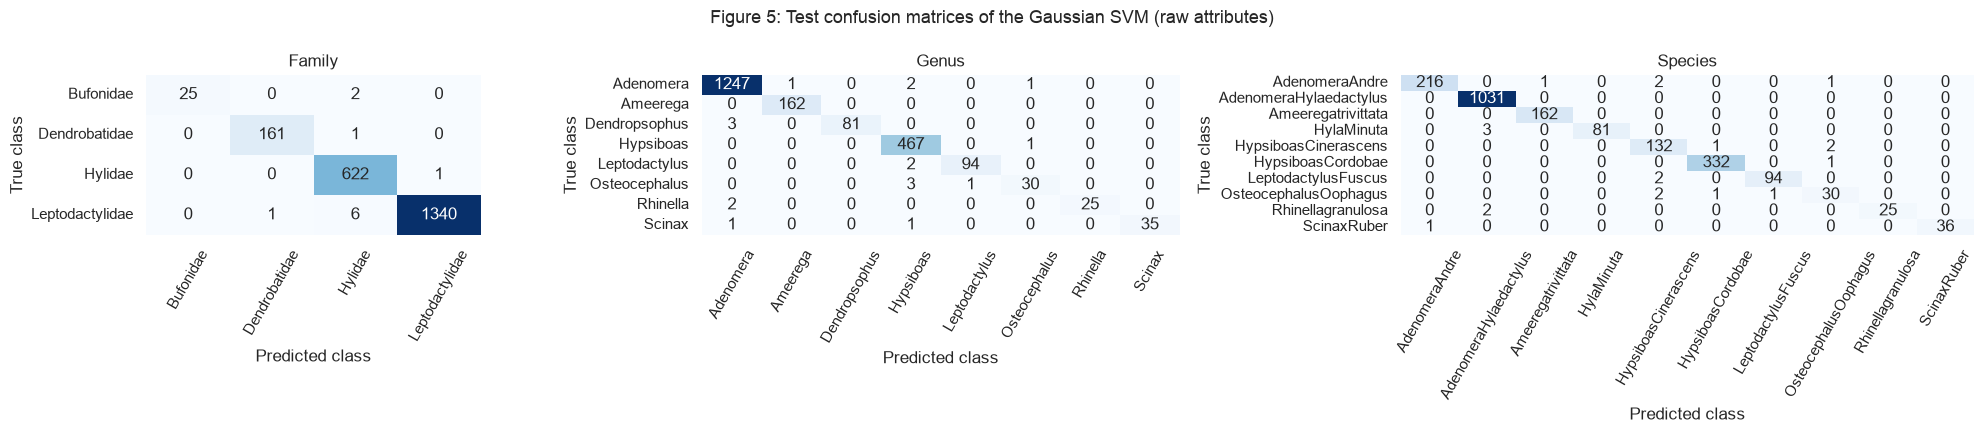

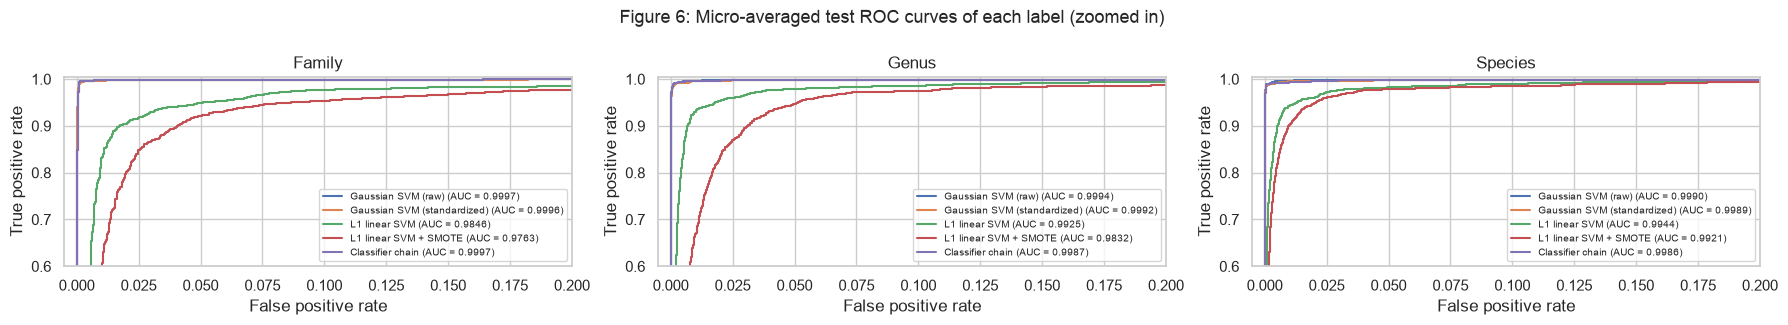

In [15]:
# confusion matrix of each label for the Gaussian SVM on raw attributes
fig, axes = plt.subplots(1, 3, figsize=(20, 4.4), gridspec_kw={"width_ratios": [0.7, 1, 1.2]})
for ax, label in zip(axes, LABELS):
    table = confusion_matrix(test_Y[label], test_preds["Gaussian SVM (raw)"][label], labels=CLASSES[label])
    sns.heatmap(table, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES[label], yticklabels=CLASSES[label], ax=ax)
    ax.set(xlabel="Predicted class", ylabel="True class", title=label)
    ax.tick_params(axis="x", rotation=60)
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("Figure 5: Test confusion matrices of the Gaussian SVM (raw attributes)", fontsize=13)
plt.tight_layout()
plt.show()

# micro-averaged ROC curve of each label for every classifier
fig, axes = plt.subplots(1, 3, figsize=(18, 3.3))
for ax, label in zip(axes, LABELS):
    true_label = label_binarize(test_Y[label], classes=CLASSES[label]).ravel()
    for name in test_preds:
        fpr, tpr, _ = roc_curve(true_label, test_scores[name][label].ravel())
        ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(true_label, test_scores[name][label].ravel()):.4f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set(xlim=(-0.005, 0.2), ylim=(0.6, 1.005), xlabel="False positive rate", ylabel="True positive rate", title=label)
    ax.legend(loc="lower right", fontsize=7)
fig.suptitle("Figure 6: Micro-averaged test ROC curves of each label (zoomed in)", fontsize=13)
plt.tight_layout()
plt.show()

**Answer.** The Gaussian SVM on the raw attributes is best again, with macro AUCs of 0.9996 (Family), 0.9973 (Genus) and 0.9973 (Species), a micro AUC of 0.9993 and macro recalls from 96.2% to 97.8%. Its micro precision and recall are both 0.9924, the same as its Hamming score. The confusion matrices (Figure 5) have almost everything on the diagonal. The most common errors are 6 Leptodactylidae rows predicted as Hylidae, and 4 of the 34 Osteocephalus rows given other genera. In the multi-label table no indicator has more than 9 false positives (Family: Hylidae) or 7 false negatives (Family: Leptodactylidae).

The L1 linear SVM has a low macro precision for Family (0.676) because no Bufonidae row is found, so that class has a precision and recall of 0. SMOTE raises its macro recall (Family from 0.690 to 0.913) but lowers the macro precision for Genus (0.924 to 0.742) and the AUC of every label, since the small classes are now predicted too often. The ROC curves (Figure 6) show the same order. The two Gaussian SVMs and the chain sit almost in the top left corner, and the linear models are well below them.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

Each Monte Carlo run fits k-means (k-means++ start) on all 7195 rows for every $k$ from 2 to 50 with its own random seed, and picks the $k$ with the largest average silhouette. The silhouette of a row is $(b - a)/\max(a, b)$, where $a$ is its average distance to the rest of its own cluster and $b$ is its average distance to the nearest other cluster. It is not defined for $k = 1$, since there is no other cluster, so $k = 1$ is left out. The raw MFCCs are used, since they are already on a common $[-1, 1]$ scale. Steps (b) and (c) are then applied to the chosen clustering of each run.

,count,mean,max
k,,,
2,6,0.349,0.349
3,12,0.369,0.373
4,25,0.381,0.385
5,1,0.370,0.370
6,6,0.379,0.381


average silhouette over the 50 runs, k = 2 to 12:
[0.349 0.345 0.318 0.3   0.292 0.274 0.265 0.262 0.262 0.259 0.259]


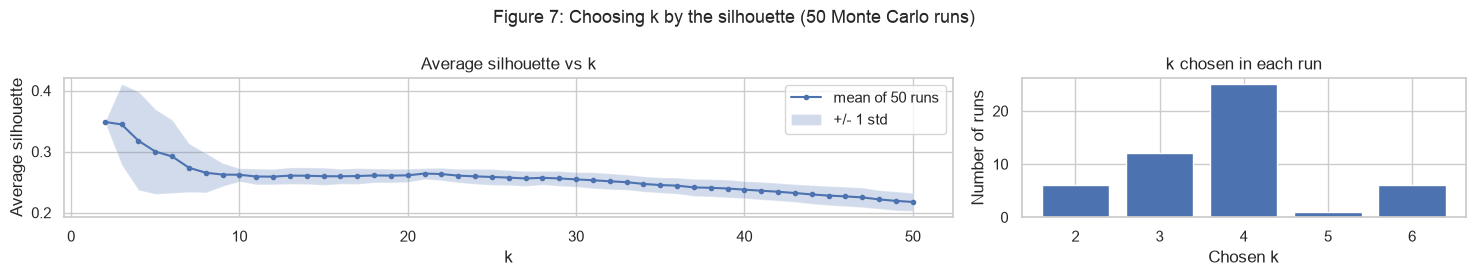

In [16]:
ALL_X = frogs_df[FEATURES].to_numpy()
K_VALUES = np.arange(2, 51)
N_RUNS = 50

def silhouette_for(seed, k):
    cluster_ids = KMeans(n_clusters=k, random_state=seed).fit_predict(ALL_X)
    # smaller distance chunks, so the parallel workers do not run out of memory
    with config_context(working_memory=64):
        return silhouette_score(ALL_X, cluster_ids)

# average silhouette of every (run, k) pair, run r uses seed r
silhouette_runs = np.array(Parallel(n_jobs=-1)(delayed(silhouette_for)(seed, k) for seed in range(N_RUNS) for k in K_VALUES)).reshape(N_RUNS, len(K_VALUES))
chosen_k = K_VALUES[silhouette_runs.argmax(axis=1)]

# refit each run with its chosen k (same seed, so the same clustering)
run_clusters = [KMeans(n_clusters=k, random_state=seed).fit_predict(ALL_X) for seed, k in enumerate(chosen_k)]

# how often each k is chosen, and the best silhouette of those runs
best_silhouettes = pd.DataFrame({"k": chosen_k, "best silhouette": silhouette_runs.max(axis=1)})
display(compact(best_silhouettes.groupby("k")["best silhouette"].agg(["count", "mean", "max"]), precision=3))
print("average silhouette over the 50 runs, k = 2 to 12:")
print(silhouette_runs.mean(axis=0)[:11].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 2.8), gridspec_kw={"width_ratios": [2, 1]})
mean_sil, std_sil = silhouette_runs.mean(axis=0), silhouette_runs.std(axis=0)
axes[0].plot(K_VALUES, mean_sil, marker="o", ms=3, label="mean of 50 runs")
axes[0].fill_between(K_VALUES, mean_sil - std_sil, mean_sil + std_sil, alpha=0.25, label="+/- 1 std")
axes[0].set(xlabel="k", ylabel="Average silhouette", title="Average silhouette vs k")
axes[0].legend()
k_counts = pd.Series(chosen_k).value_counts().sort_index()
axes[1].bar(k_counts.index.astype(str), k_counts.values)
axes[1].set(xlabel="Chosen k", ylabel="Number of runs", title="k chosen in each run")
fig.suptitle("Figure 7: Choosing k by the silhouette (50 Monte Carlo runs)", fontsize=13)
plt.tight_layout()
plt.show()

**Answer.** The chosen $k$ depends on the run. **$k = 4$ is chosen in 25 of the 50 runs**, $k = 3$ in 12, $k = 2$ and $k = 6$ in 6 each and $k = 5$ once (Figure 7, right). It changes because k-means from a different random start ends in a different local optimum for $k$ from 3 to 6, which is the wide band in Figure 7 (left). The runs that pick $k = 4$ reach a silhouette of 0.381 on average (at most 0.385), and in the runs that pick $k = 2$ or 3 the 4-cluster fit landed in a worse optimum. Averaged over all runs the curve is highest at $k = 2$ (0.349) and $k = 3$ (0.345), stays near 0.26 from $k = 10$ to about 22, and then slowly falls. The best silhouettes are below 0.39, so the clusters overlap, and the 10 species are not 10 well separated groups.

### (b) Determine which family is the majority

In [17]:
def most_common(col):
    return col.value_counts().idxmax()

def majority_labels(cluster_ids):
    # most common family, genus and species in each cluster
    majority = frogs_df[LABELS].groupby(cluster_ids).agg(most_common)
    majority.insert(0, "size", np.bincount(cluster_ids))
    return majority

def purity(cluster_ids, majority):
    # share of each cluster that has the majority label
    assigned = majority.loc[cluster_ids, LABELS].to_numpy()
    return pd.DataFrame(frogs_df[LABELS].to_numpy() == assigned, columns=LABELS).groupby(cluster_ids).mean()

# the clustering of the first run
first_ids = run_clusters[0]
first_majority = majority_labels(first_ids)
shares = (100 * purity(first_ids, first_majority)).add_suffix(" (%)")
print(f"Run 1 (k = {chosen_k[0]}): majority label of each cluster and the share with that label")
display(compact(first_majority.join(shares), precision=2))

# which majority triplets appear across the 50 runs
triplet_counts = pd.Series([row for cluster_ids in run_clusters for row in majority_labels(cluster_ids)[LABELS].itertuples(index=False, name=None)]).value_counts()
triplet_table = pd.DataFrame(triplet_counts.index.tolist(), columns=LABELS)
triplet_table["clusters"] = triplet_counts.to_numpy()
print("majority triplets over all 50 runs:")
display(compact(triplet_table).hide(axis="index"))

Run 1 (k = 4): majority label of each cluster and the share with that label


,size,Family,Genus,Species,Family (%),Genus (%),Species (%)
0,3584,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,96.79,96.71,96.71
1,2216,Hylidae,Hypsiboas,HypsiboasCordobae,57.40,42.69,42.64
2,663,Hylidae,Hypsiboas,HypsiboasCinerascens,95.78,85.07,68.02
3,732,Leptodactylidae,Adenomera,AdenomeraAndre,79.37,50.41,50.41


majority triplets over all 50 runs:


Family,Genus,Species,clusters
Hylidae,Hypsiboas,HypsiboasCordobae,61
Leptodactylidae,Adenomera,AdenomeraHylaedactylus,50
Leptodactylidae,Adenomera,AdenomeraAndre,31
Hylidae,Hypsiboas,HypsiboasCinerascens,24
Dendrobatidae,Ameerega,Ameeregatrivittata,18
Hylidae,Leptodactylus,LeptodactylusFuscus,4
Leptodactylidae,Leptodactylus,LeptodactylusFuscus,1


**Answer.** The first table is the first run ($k = 4$). The largest cluster (3584 rows) is AdenomeraHylaedactylus, and 97% of it really is that species. The other three clusters are labeled (Hylidae, Hypsiboas, HypsiboasCordobae), (Hylidae, Hypsiboas, HypsiboasCinerascens) and (Leptodactylidae, Adenomera, AdenomeraAndre). The HypsiboasCordobae cluster is the most mixed, with only 57% Hylidae and 43% HypsiboasCordobae.

Over all 50 runs only six species are ever a cluster majority (last table). The small species, like Rhinellagranulosa (68 rows), ScinaxRuber, OsteocephalusOophagus and HylaMinuta, never are, so their rows always get a wrong label. The majority is found for each label on its own, so the triplet of a cluster is not always a real species. **(Hylidae, Leptodactylus, LeptodactylusFuscus)** shows up in 4 clusters, although Leptodactylus belongs to Leptodactylidae.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

Every row gets the majority triplet of its cluster, and it is compared with its true triplet using the definitions from 1(b)i. The Hamming distance of a row is the number of its 3 labels that are wrong, the Hamming loss is the average distance divided by 3, and the Hamming score is 1 minus the loss.

In [18]:
run_rows = []
for seed, (k, cluster_ids) in enumerate(zip(chosen_k, run_clusters)):
    assigned = majority_labels(cluster_ids).loc[cluster_ids, LABELS].to_numpy()
    run_rows.append({"run": seed + 1, "k": int(k), **multilabel_scores(frogs_df[LABELS], assigned)})
run_df = pd.DataFrame(run_rows).set_index("run")

# all 50 runs as two blocks of 25, the score of each run is 100 - loss
print("loss in %")
display(side_by_side(short_table(run_df)[["k", "distance", "loss"]]))

# average and standard deviation over the 50 runs
print("exact, loss and score in %:")
display(compact(short_table(run_df.drop(columns="k").agg(["mean", "std"]))))

loss in %


exact, loss and score in %:


,exact,distance,loss,score
mean,71.2050,0.7187,23.9556,76.0444
std,5.4418,0.1309,4.3637,4.3637


**Answer.** Over the 50 runs the **average Hamming distance is 0.7187 with a standard deviation of 0.1309**. The Hamming loss is 23.96% (standard deviation 4.36%) and the Hamming score 76.04% (4.36%), and the exact match ratio is 71.21% (5.44%). The loss is the distance divided by 3, so its standard deviation is also a third of the distance's.

So on average a row gets 0.72 of its 3 labels wrong. For comparison, giving every row the most common triplet (Leptodactylidae, Adenomera, AdenomeraHylaedactylus) gives a Hamming distance of $(2775 + 3045 + 3717)/7195 = 1.33$, so the clusters about halve that. They are still far from the supervised Gaussian SVM in 1(b)ii (0.023 on the test set). K-means never sees the labels, and most of its correct labels come from the large AdenomeraHylaedactylus cluster.

## 3. ISLR 12.6.2

*Suppose that we have four observations, for which we compute a dissimilarity matrix, given by*
$$\begin{bmatrix} & 0.3 & 0.4 & 0.7 \\ 0.3 & & 0.5 & 0.8 \\ 0.4 & 0.5 & & 0.45 \\ 0.7 & 0.8 & 0.45 & \end{bmatrix}.$$
*For instance, the dissimilarity between the first and second observations is 0.3, and the dissimilarity between the second and fourth observations is 0.8.*

**(a)** *On the basis of this dissimilarity matrix, sketch the dendrogram that results from hierarchically clustering these four observations using complete linkage. Be sure to indicate on the plot the height at which each fusion occurs, as well as the observations corresponding to each leaf in the dendrogram.* **Answer.** The smallest dissimilarity is $d(1, 2) = 0.3$, so 1 and 2 fuse first, at height 0.3. Complete linkage uses the largest dissimilarity between two clusters, so $d(\{1, 2\}, 3) = \max(0.4, 0.5) = 0.5$, $d(\{1, 2\}, 4) = \max(0.7, 0.8) = 0.8$ and $d(3, 4) = 0.45$. The smallest is 0.45, so 3 and 4 fuse at 0.45. Last, $d(\{1, 2\}, \{3, 4\}) = \max(0.4, 0.7, 0.5, 0.8) = 0.8$, so the two pairs fuse at 0.8 (Figure 8, left).

**(b)** *Repeat (a), this time using single linkage clustering.* **Answer.** Again 1 and 2 fuse first at 0.3. Single linkage uses the smallest dissimilarity, so $d(\{1, 2\}, 3) = \min(0.4, 0.5) = 0.4$, $d(\{1, 2\}, 4) = \min(0.7, 0.8) = 0.7$ and $d(3, 4) = 0.45$. The smallest is 0.4, so 3 joins $\{1, 2\}$ at 0.4. Last, $d(\{1, 2, 3\}, 4) = \min(0.7, 0.8, 0.45) = 0.45$, so 4 joins at 0.45 (Figure 8, middle).

complete linkage, two clusters: [[1, 2], [3, 4]]
single linkage, two clusters: [[1, 2, 3], [4]]


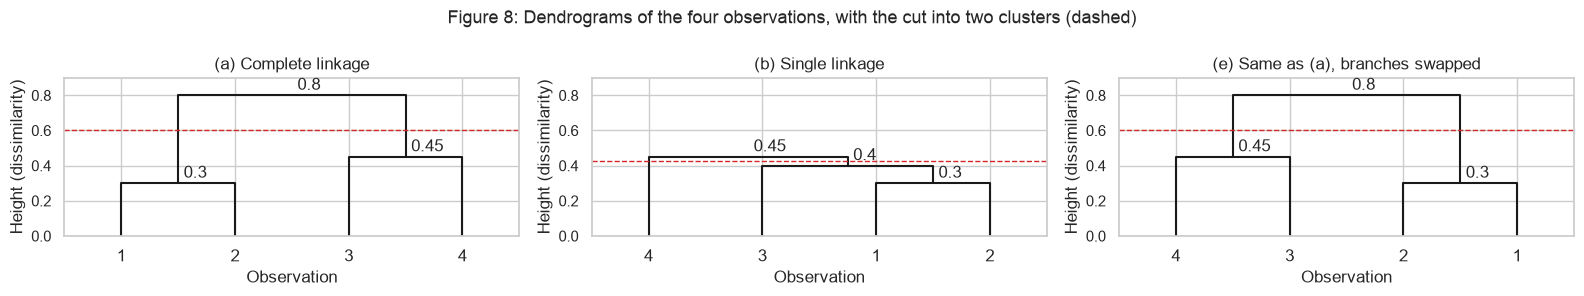

In [19]:
DISSIMILARITY = np.array([[0, 0.3, 0.4, 0.7],
                          [0.3, 0, 0.5, 0.8],
                          [0.4, 0.5, 0, 0.45],
                          [0.7, 0.8, 0.45, 0]])
OBS_NAMES = ["1", "2", "3", "4"]

complete_tree = linkage(squareform(DISSIMILARITY), method="complete")
single_tree = linkage(squareform(DISSIMILARITY), method="single")
# one row per fusion, clusters 0 to 3 are observations 1 to 4
fusions = pd.concat({name: pd.DataFrame(tree, columns=["cluster 1", "cluster 2", "height", "size"]) for name, tree in [("complete", complete_tree), ("single", single_tree)]}, names=["linkage", "step"])
display(side_by_side(fusions.astype({"cluster 1": int, "cluster 2": int, "size": int})))

# cut each tree into two clusters
for name, tree in [("complete", complete_tree), ("single", single_tree)]:
    cluster_ids = fcluster(tree, t=2, criterion="maxclust")
    print(f"{name} linkage, two clusters:", [[int(obs) + 1 for obs in np.where(cluster_ids == c)[0]] for c in np.unique(cluster_ids)])

# (e) swap the two branches at every fusion of the complete linkage tree
swapped_tree = complete_tree.copy()
swapped_tree[:, [0, 1]] = swapped_tree[:, [1, 0]]

def plot_dendrogram(ax, tree, title, cut):
    info = dendrogram(tree, labels=OBS_NAMES, ax=ax, color_threshold=0, above_threshold_color="k")
    # write the fusion height next to each merge
    for xs, ys in zip(info["icoord"], info["dcoord"]):
        ax.annotate(f"{ys[1]:g}", (np.mean(xs[1:3]), ys[1]), textcoords="offset points", xytext=(4, 4), ha="left")
    ax.axhline(cut, color="tab:red", ls="--", lw=1)
    ax.set(title=title, xlabel="Observation", ylabel="Height (dissimilarity)", ylim=(0, 0.9))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.0))
plot_dendrogram(axes[0], complete_tree, "(a) Complete linkage", cut=0.6)
plot_dendrogram(axes[1], single_tree, "(b) Single linkage", cut=0.425)
plot_dendrogram(axes[2], swapped_tree, "(e) Same as (a), branches swapped", cut=0.6)
fig.suptitle("Figure 8: Dendrograms of the four observations, with the cut into two clusters (dashed)", fontsize=13)
plt.tight_layout()
plt.show()

**(c)** *Suppose that we cut the dendrogram obtained in (a) such that two clusters result. Which observations are in each cluster?* **Answer.** Cutting the complete linkage tree anywhere between 0.45 and 0.8 gives **$\{1, 2\}$ and $\{3, 4\}$**.

**(d)** *Suppose that we cut the dendrogram obtained in (b) such that two clusters result. Which observations are in each cluster?* **Answer.** Cutting the single linkage tree between 0.4 and 0.45 gives **$\{1, 2, 3\}$ and $\{4\}$**.

**(e)** *It is mentioned in the chapter that at each fusion in the dendrogram, the position of the two clusters being fused can be swapped without changing the meaning of the dendrogram. Draw a dendrogram that is equivalent to the dendrogram in (a), for which two or more of the leaves are repositioned, but for which the meaning of the dendrogram is the same.* **Answer.** Swapping the two branches at every fusion of the complete linkage tree gives the leaf order 4, 3, 2, 1 instead of 1, 2, 3, 4 (Figure 8, right). The fusions and their heights stay the same (1 with 2 at 0.3, 3 with 4 at 0.45, and the two pairs at 0.8), so both dendrograms say the same thing. Only the heights of the fusions carry meaning, not how close two leaves are drawn along the horizontal axis.

## 4. Extra Practice

The extra practice problems (the rest of ISLR 12.6: 12.6.1 and 12.6.3 to 12.6.13) are answered in `Raza_MohammadHasnain_HW7_Extra.ipynb`, in the same `notebook` folder.

### References

1. UCI Machine Learning Repository, [*Anuran Calls (MFCCs) Data Set*](https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs).
2. J. G. Colonna, J. Gama, E. F. Nakamura, "Recognizing family, genus, and species of anuran using a hierarchical classification approach," *Lecture Notes in Computer Science*, 9956 (2016), 198-212.
3. M. S. Sorower, "A literature survey on algorithms for multi-label learning," Oregon State University (2010).
4. G. Tsoumakas, I. Katakis, "Multi-label classification: An overview," *International Journal of Data Warehousing and Mining*, 3(3) (2007), 1-13.
5. J. Read, B. Pfahringer, G. Holmes, E. Frank, "Classifier chains for multi-label classification," *Machine Learning*, 85 (2011), 333-359.
6. C. Cortes, V. Vapnik, "Support-vector networks," *Machine Learning*, 20 (1995), 273-297.
7. C.-W. Hsu, C.-C. Chang, C.-J. Lin, "A practical guide to support vector classification," National Taiwan University (2003).
8. J. Zhu, S. Rosset, T. Hastie, R. Tibshirani, "1-norm support vector machines," *Advances in Neural Information Processing Systems*, 16 (2003).
9. R.-E. Fan, K.-W. Chang, C.-J. Hsieh, X.-R. Wang, C.-J. Lin, "LIBLINEAR: A library for large linear classification," *Journal of Machine Learning Research*, 9 (2008), 1871-1874.
10. N. V. Chawla, K. W. Bowyer, L. O. Hall, W. P. Kegelmeyer, "SMOTE: Synthetic minority over-sampling technique," *Journal of Artificial Intelligence Research*, 16 (2002), 321-357.
11. P. J. Rousseeuw, "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis," *Journal of Computational and Applied Mathematics*, 20 (1987), 53-65.
12. D. Arthur, S. Vassilvitskii, "k-means++: The advantages of careful seeding," *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms* (2007), 1027-1035.
13. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (ISLR), 2nd ed., Ch. 9 (support vector machines) and Ch. 12.4 (K-means and hierarchical clustering).
14. [scikit-learn User Guide](https://scikit-learn.org/stable/user_guide.html), *Support Vector Machines*, *Multiclass and multioutput algorithms*, *Model evaluation* and *Clustering*.
15. imbalanced-learn User Guide, [*Over-sampling*](https://imbalanced-learn.org/stable/over_sampling.html).